Read the [accompanying blog post](https://acytoo.com/ladder/llm-tut-1-gpt2/) for explanations and experiment results.

## Data

In [ ]:
!wget https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -O names.txt -o /dev/null

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
words = open('names.txt', 'r').read().splitlines()

In [ ]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

### Dataset

In [ ]:
# bulid the dataset
def build_dataset(words):
    block_size = 3
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(23)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182400, 3]) torch.Size([182400])
torch.Size([22887, 3]) torch.Size([22887])
torch.Size([22859, 3]) torch.Size([22859])


### MLP model

In [ ]:
g = torch.Generator().manual_seed(123456)
C = torch.randn((27, 10), generator=g) # embedding space, 27 tows with each row has 10 elements, the representation of the char in a 10-D space
w1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
w2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True


11897


In [ ]:
lri = []
lossi = []
stepi = []

### Train

In [ ]:
for i in range(50000):

    # mini batch
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # the embdding for input X
    h = torch.tanh(emb.view(-1, 30) @ w1 + b1) # hiden layer
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    stepi.append(i)
    lossi.append(loss.log10().item())
print(loss.item())


2.627366065979004


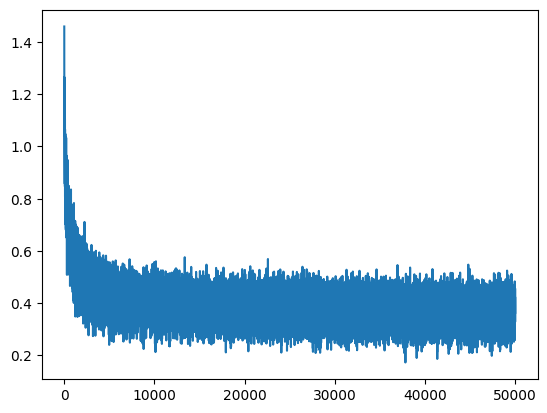

In [ ]:
plt.plot(stepi, lossi)

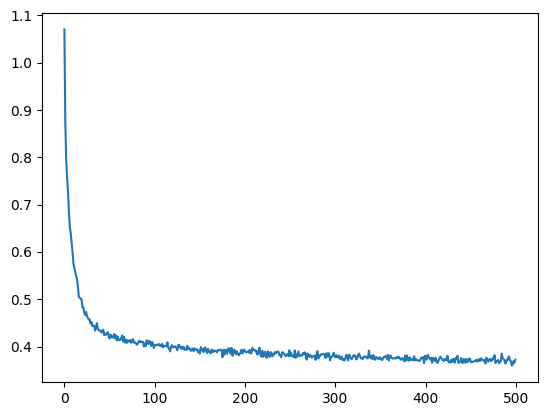

In [ ]:
plt.plot(torch.tensor(lossi).view(-1, 100).mean(1))

In [ ]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ w1 + b1)
logits = h @ w2 + b2
loss_all = F.cross_entropy(logits, Ydev)
loss_all

tensor(2.3535, grad_fn=<NllLossBackward0>)

### Visualize embedding

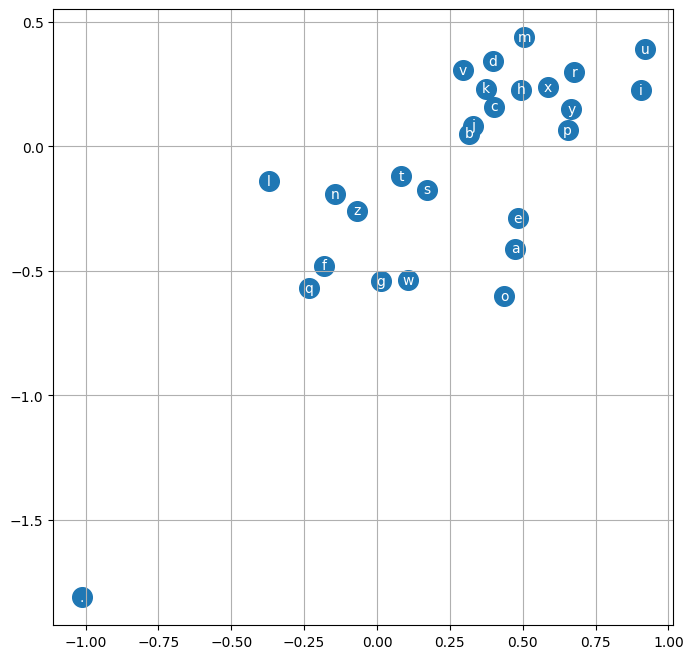

In [ ]:
plt.figure(figsize=(8,8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i][1].item(), itos[i], ha='center', va='center', color='white')
plt.grid('minor')

### Sampling

In [ ]:
block_size = 3
g = torch.Generator().manual_seed(1234567)
for _ in range(10):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor(context)]
        h = torch.tanh(emb.view(1, -1) @ w1 + b1)
        logits = h @ w2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))



mikaralynn.
ajayalan.
shelyn.
jyliesca.
menahyushity.
hulihaa.
shiliyah.
jeiyah.
vovebelli.
ull.
